In [ ]:
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio as rio
from matplotlib import pyplot as plt
import cartopy.crs as ccrs
from pathlib import Path

In [ ]:
ROOT = Path.cwd().parent
DATA = ROOT / "data"
RESULTS = ROOT / "results"
FIGURES = ROOT / "figures"

In [4]:
country_pseudo_values = pd.read_csv(DATA / 'country-pseudo-values.csv')

In [5]:
region_code = dict({
    1: 'Middle East', 
    2: 'Latin America and the Caribbean',
    3: 'North Africa', 
    4: 'West Africa',
    5: 'East Africa',
    6: 'Central Africa',
    7: 'Southern Africa',
    8: 'Europe', 
    9: 'South-eastern Asia', 
    10: 'Oceania',
    11: 'Southern Asia', 
    12: 'Eastern Asia', 
    13: 'Central and Northern Asia', 
    14: 'Northern America',
    15: 'China'
})

In [6]:
region_abbr = dict({
    1: 'ME', 
    2: 'LAC',
    3: 'NAF', 
    4: 'WAF',
    5: 'EAF',
    6: 'CAF',
    7: 'SAF',
    8: 'EU', 
    9: 'SEA', 
    10: 'OC',
    11: 'SA', 
    12: 'EA', 
    13: 'CNA', 
    14: 'NA',
    15: 'CHN'
})

In [8]:
world_map_ = gpd.read_file(DATA / 'simplified-world-map' / 'world-map.shp')
world_map_['geometry'] = world_map_.buffer(0)
world_map = world_map_.drop([31])
world_map = world_map.to_crs('ESRI:54012')

In [9]:
country_raster_1km_  = rio.open(RESULTS / 'country-rasters' / 'country-raster-eck4-1km.tif')
country_raster_10km_  = rio.open(RESULTS / 'country-rasters' / 'country-raster-eck4-10km.tif')
country_raster_1km = country_raster_1km_.read(1)

In [10]:
country_region = country_pseudo_values[['country', 'region']].rename(columns={'country': 'GID_0'})
world_map_region = world_map.merge(country_region, on='GID_0', how='left')

region_colors = {
    'Middle East': "#e41a1c",   # Middle East
    'Latin America and the Caribbean': "#377eb8",   # Latin America
    'North Africa': "#4daf4a",   # North Africa
    'West Africa': "#984ea3",   # West Africa
    'East Africa': "#ff7f00",   # East Africa
    'Central Africa': "#ffff33",   # Central Africa
    'Southern Africa': "#a65628",   # Southern Africa
    'Europe': "#f781bf",   # Europe
    'South-eastern Asia': "#999999",   # SE Asia
    'Oceania': "#66c2a5",  # Oceania
    'Southern Asia': "#fc8d62",  # Southern Asia
    'Eastern Asia': "#8da0cb",  # Eastern Asia
    'Central and Northern Asia': "#8ae7bc",  # Central & N Asia
    'Northern America': "#a6d854",  # North America
    'China': "#ffd92f",  # China
}

world_map_region["color"] = world_map_region["region"].map(region_colors)

In [21]:
global_quarries_ = gpd.read_file(DATA / 'global-aggregate-quarries-210101.gpkg')
global_quarries = global_quarries_.to_crs('ESRI:54012')
global_quarries_pt = global_quarries.copy()
global_quarries_pt["geometry"] = global_quarries_pt.geometry.representative_point()

In [ ]:
global_quarry_area_grid = rio.open(RESULTS / 'quarry-area-rasters' / 'global-aggregate-quarry-area-raster-1km.tif').read(1)

In [17]:
presence_grid = np.ma.masked_where(
    global_quarry_area_grid <= 0,
    np.ones_like(global_quarry_area_grid, dtype=np.uint8)
)

In [19]:
display_extent_1km = [country_raster_1km_.bounds.left, country_raster_1km_.bounds.right, country_raster_1km_.bounds.bottom, country_raster_1km_.bounds.top]

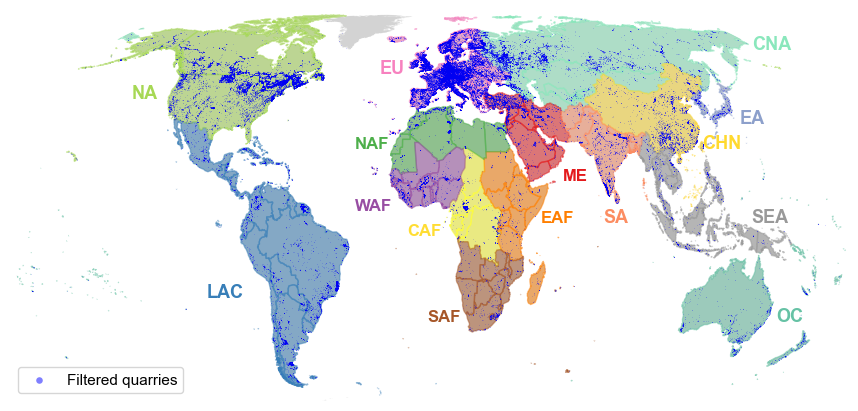

In [ ]:
fig = plt.figure(figsize=(8.5, 4), constrained_layout=True)
plt.rcParams['font.family'] = 'Arial' 

ax1 = plt.subplot(111, projection=ccrs.EckertIV())

world_map.plot(color='lightgrey', edgecolor='none', lw=0.2, ax=ax1, zorder=1)
# world_map.plot(color='none', edgecolor='grey', lw=0.2, ax=ax1, zorder=10)
for r, sub in world_map_region.groupby("region"):
    sub.plot(
        ax=ax1,
        facecolor=region_colors.get(r, 'black'),
        edgecolor=region_colors.get(r, 'black'),
        linewidth=1.0,
        alpha=0.5
    )

# ax1.imshow(presence_grid,cmap='Blues', vmin=0, vmax=1, interpolation='nearest', origin='upper', extent=display_extent_1km, zorder=10)
global_quarries_pt.plot(color='blue', markersize=0.1, lw=0.0, alpha=0.5, zorder=11, label='Filtered quarries', ax=ax1)
ax1.legend(fontsize=11, loc='lower left', markerscale=15, frameon=True)
ax1.set_ylim(-7.2e6, 8.6e6)
ax1.axis('off')

ax1.text(5.4e6, 1.7e6, 'ME', color="#e41a1c", fontdict={'size': 12, 'weight': 'semibold'})
ax1.text(-9e6, -3e6, 'LAC', color="#377eb8", fontdict={'size': 13, 'weight': 'semibold'})
ax1.text(-3e6, 3e6, 'NAF', color="#4daf4a", fontdict={'size': 12, 'weight': 'semibold'})
ax1.text(-3e6, 0.5e6, 'WAF', color="#984ea3", fontdict={'size': 12, 'weight': 'semibold'})
ax1.text(4.5e6, 0e6, 'EAF', color="#ff7f00", fontdict={'size': 12, 'weight': 'semibold'})
ax1.text(-0.9e6, -0.5e6, 'CAF', color="#ffdd33", fontdict={'size': 12, 'weight': 'semibold'})
ax1.text(-0.1e6, -4e6, 'SAF', color="#a65628", fontdict={'size': 12, 'weight': 'semibold'})
ax1.text(-2e6, 6e6, 'EU', color="#f781bf", fontdict={'size': 13, 'weight': 'semibold'})
ax1.text(13e6, 0e6, 'SEA', color="#999999", fontdict={'size': 13, 'weight': 'semibold'})
ax1.text(7e6, 0e6, 'SA', color="#fc8d62", fontdict={'size': 13, 'weight': 'semibold'})
ax1.text(12.5e6, 4e6, 'EA', color="#8da0cb", fontdict={'size': 13, 'weight': 'semibold'})
ax1.text(13e6, 7e6, 'CNA', color="#8ae7bc", fontdict={'size': 13, 'weight': 'semibold'})
ax1.text(-12e6, 5e6, 'NA', color="#a6d854", fontdict={'size': 13, 'weight': 'semibold'})
ax1.text(14e6, -4e6, 'OC', color="#66c2a5", fontdict={'size': 13, 'weight': 'semibold'})
ax1.text(11.0e6, 3e6, 'CHN', color="#ffd92f", fontdict={'size': 13, 'weight': 'semibold'})

plt.savefig(FIGURES / 'Supplementary-Figure-11.jpg', dpi=600, bbox_inches='tight')
plt.show()